# 04 · Predicting which stops matter (surrogate model)

**The problem:** finding out exactly how much damage closing a stop causes means removing it and recomputing every fastest path in the network. Doing that for all 1,853 LBT stops is the "exhaustive simulation".

**The idea:** train a model on cheap per-stop features (`transitshock.features`) to predict that damage without running the simulation.

**Label:** `efficiency_loss`, the share of network efficiency lost when one stop is removed.

**Build the dataset first** (features plus exhaustive labels, about 1 minute on 10 cores):
```
python -m transitshock.features data/processed/lbt_20261104.gpickle
```

In [1]:
from pathlib import Path

import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold

from transitshock.features import FEATURES
from transitshock.model import MODELS, TARGET, compare, fit, out_of_fold_predictions, score, spatial_groups

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

df = pd.read_csv(PROCESSED / "lbt_20261104_dataset.csv", index_col="node")
timings = pd.read_csv(PROCESSED / "lbt_20261104_timings.csv", index_col=0)["seconds"]
print(f"{len(df)} stops, {len(FEATURES)} features")
df[FEATURES].describe().T.round(3)

1853 stops, 13 features


,count,mean,std,min,25%,50%,75%,max
trips_per_day,1853.0,49.485,33.558,1.000,29.000,33.000,65.000,327.000
n_routes,1853.0,1.633,1.058,1.000,1.000,1.000,2.000,9.000
transit_in,1853.0,1.074,0.295,0.000,1.000,1.000,1.000,4.000
transit_out,1853.0,1.074,0.300,0.000,1.000,1.000,1.000,4.000
walk_degree,1853.0,2.099,1.456,0.000,1.000,2.000,3.000,10.000
is_terminus,1853.0,0.004,0.066,0.000,0.000,0.000,0.000,1.000
nearest_stop_m,1853.0,66.412,59.750,10.280,35.245,50.886,71.828,568.348
bypass_gap_m,1853.0,711.631,1228.249,0.000,484.921,637.374,807.682,37148.730
betweenness,1853.0,0.015,0.013,0.000,0.005,0.011,0.020,0.094
harmonic_in,1853.0,0.001,0.000,0.000,0.001,0.001,0.001,0.001


## 1. What does the ground truth look like?

Removing a stop always loses its own pairs (0.108% of all pairs).
211 of 1853 stops (11%) also cut OTHER stops off from each other.


,efficiency_loss,reachable_loss,added_min
count,1853.00000,1853.00000,1853.00000
mean,0.00241,0.00144,0.03207
std,0.00110,0.00142,0.05641
min,0.00021,0.00108,-0.44659
25%,0.00166,0.00108,0.00989
50%,0.00218,0.00108,0.02445
75%,0.00290,0.00108,0.05275
max,0.01013,0.01600,0.42587


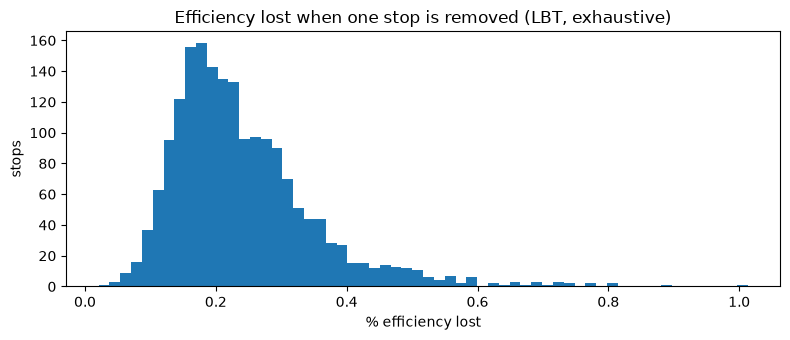

In [2]:
n = len(df)
own_pairs = 2 / n  # share of pairs every removal loses just by deleting the stop itself
cuts_others = df["reachable_loss"] > own_pairs + 1e-9
print(f"Removing a stop always loses its own pairs ({own_pairs:.3%} of all pairs).")
print(f"{cuts_others.sum()} of {n} stops ({cuts_others.mean():.0%}) also cut OTHER stops off from each other.")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(df[TARGET] * 100, bins=60)
ax.set(title="Efficiency lost when one stop is removed (LBT, exhaustive)", xlabel="% efficiency lost", ylabel="stops")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_damage_distribution.png", dpi=150)
df[[TARGET, "reachable_loss", "added_min"]].describe().round(5)

In [3]:
cols = ["name", TARGET, "reachable_loss", "betweenness", "trips_per_day", "bypass_gap_m"]
df.nlargest(15, TARGET)[cols].round(4)

,name,efficiency_loss,reachable_loss,betweenness,trips_per_day,bypass_gap_m
node,,,,,,
lbt:1504,223rd and Avalon NW,0.0101,0.0160,0.0338,44.0,549.1586
lbt:0255,Cherry & Wardlow SW,0.0088,0.0011,0.0935,92.0,426.0551
lbt:0256,Cherry & 33rd SW,0.0081,0.0011,0.0763,92.0,789.8760
lbt:4124,Studebaker & Artesia SW,0.0080,0.0133,0.0154,72.0,1358.4296
lbt:1596,Del Amo & Long Beach Blvd NW,0.0077,0.0011,0.0530,65.0,449.7801
lbt:4101,Studebaker & Artesia NE,0.0077,0.0133,0.0123,34.0,1349.2782
lbt:1506,223rd and Grace NW,0.0074,0.0128,0.0118,44.0,792.4244
lbt:1597,Del Amo & Daisy NW,0.0074,0.0011,0.0471,65.0,1560.4203
lbt:4102,Studebaker & Spinnaker SE,0.0072,0.0128,0.0117,34.0,813.1057


In [4]:
# Map: stop color and size by damage. Saved to figures/lbt_damage_map.html.
m = folium.Map(location=[df["lat"].mean(), df["lon"].mean()], zoom_start=12)
top = df[TARGET].quantile(0.95)
for node, r in df.sort_values(TARGET).iterrows():
    critical = r[TARGET] >= top
    folium.CircleMarker(
        [r["lat"], r["lon"]], radius=6 if critical else 2,
        color="#D62028" if critical else "#555555", fill=True, fill_opacity=0.8, weight=0,
        popup=f"{r['name']}: {r[TARGET]:.3%} efficiency lost",
    ).add_to(m)
m.save(FIGURES / "lbt_damage_map.html")
print("red = top 5% most damaging stops")

red = top 5% most damaging stops


## 2. Heuristics vs. trained models

Every model is scored on stops it **never saw during training** (5-fold cross-validation). There are two ways to split:
- **Random folds:** stops are shuffled into folds. This is optimistic, because a stop's next-door neighbor (with nearly identical features) is often in the training set.
- **Spatial folds:** stops are clustered into 10 neighborhoods, and each fold holds out whole neighborhoods. This is the honest test of whether the model works on a part of the city it hasn't seen.

Scores:
- **R²:** how close the predicted values are to the true ones.
- **Spearman ρ:** how well the predicted ranking matches the true ranking.
- **Top-5% overlap:** of the 93 truly most damaging stops, how many the model also puts in its top 93.

In [5]:
%%time
groups = spatial_groups(df, n_groups=10)
results = pd.concat({
    "random folds": compare(df),
    "spatial folds": compare(df, groups=groups),
}, axis=1).round(3)
results

CPU times: user 1min 46s, sys: 1min 24s, total: 3min 11s
Wall time: 22.4 s


random folds                       spatial folds  \
                                   r2 spearman top5_overlap            r2   
heuristic: betweenness            NaN    0.796        0.473           NaN   
heuristic: trips_per_day          NaN   -0.018        0.032           NaN   
heuristic: n_routes               NaN    0.009        0.022           NaN   
heuristic: harmonic_in            NaN    0.505        0.215           NaN   
heuristic: bypass_gap_m           NaN    0.154        0.108           NaN   
model: ridge                    0.439    0.775        0.430      -848.166   
model: random_forest            0.728    0.888        0.602         0.589   
model: gradient_boosting        0.738    0.899        0.613         0.540   

                                                
                         spearman top5_overlap  
heuristic: betweenness      0.796        0.473  
heuristic: trips_per_day   -0.018        0.032  
heuristic: n_routes         0.009        0.022  
heuristic: harmonic_in      0.505        0.215  
heuristic: bypass_gap_m     0.154        0.108  
model: ridge                0.739        0.419  
model: random_forest        0.811        0.505  
model: gradient_boosting    0.794        0.419

## 3. How close are the predictions? (random forest, spatial folds)

r2              0.589
spearman        0.811
top5_overlap    0.505
dtype: float64

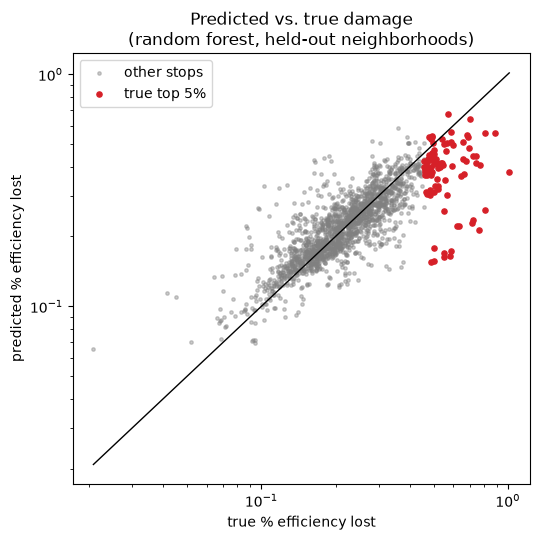

In [6]:
pred = out_of_fold_predictions(df, MODELS["random_forest"], groups=groups)
df["predicted"] = pred

fig, ax = plt.subplots(figsize=(5.5, 5.5))
critical = df[TARGET] >= df[TARGET].quantile(0.95)
ax.scatter(df.loc[~critical, TARGET] * 100, df.loc[~critical, "predicted"] * 100, s=6, alpha=0.4, color="gray", label="other stops")
ax.scatter(df.loc[critical, TARGET] * 100, df.loc[critical, "predicted"] * 100, s=14, color="#D62028", label="true top 5%")
lims = [df[[TARGET, "predicted"]].min().min() * 100, df[[TARGET, "predicted"]].max().max() * 100]
ax.plot(lims, lims, color="black", lw=1)
ax.set(xscale="log", yscale="log", xlabel="true % efficiency lost", ylabel="predicted % efficiency lost",
       title="Predicted vs. true damage\n(random forest, held-out neighborhoods)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "lbt_predicted_vs_true.png", dpi=150)
pd.Series(score(df[TARGET], pred)).round(3)

## 4. Which features does the model rely on?

**Permutation importance:** shuffle one feature in the held-out stops and measure how much worse the predictions get. A big drop means the model depends on that feature. This is computed on held-out neighborhoods, so it reflects what generalizes.

CPU times: user 25 s, sys: 4.14 s, total: 29.1 s
Wall time: 18.7 s


betweenness       1.344
dist_center_km    0.120
harmonic_in       0.021
trips_per_day     0.011
bypass_gap_m      0.010
pagerank          0.008
harmonic_out      0.007
walk_degree       0.002
transit_in        0.001
n_routes          0.001
is_terminus      -0.000
transit_out      -0.000
nearest_stop_m   -0.004
dtype: float64

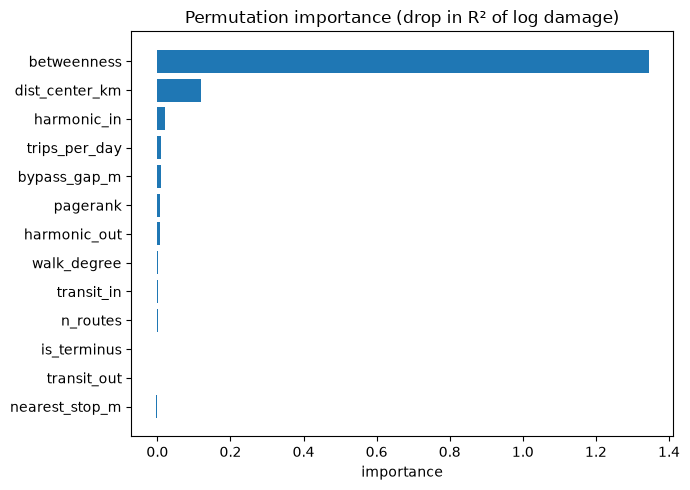

In [7]:
%%time
X, y = df[FEATURES].to_numpy(), np.log(df[TARGET].to_numpy())
importances = []
for train, test in GroupKFold(5).split(X, y, groups):
    model = clone(MODELS["random_forest"]).fit(X[train], y[train])
    r = permutation_importance(model, X[test], y[test], n_repeats=10, random_state=0, scoring="r2")
    importances.append(r.importances_mean)
importance = pd.Series(np.mean(importances, axis=0), index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importance.index, importance.values, color="#1f77b4")
ax.set(title="Permutation importance (drop in R² of log damage)", xlabel="importance")
fig.tight_layout()
fig.savefig(FIGURES / "lbt_feature_importance.png", dpi=150)
importance.sort_values(ascending=False).round(3)

## 5. Is it actually faster?

Exhaustive simulation: one full network evaluation per stop. Surrogate: compute the features once, then run the model.

*Wall* time is how long you wait. *CPU* time is the total work, roughly what it would take on one core.

In [8]:
final = fit(df)
import time
t = time.perf_counter()
_ = np.exp(final.predict(df[FEATURES].to_numpy()))
predict_s = time.perf_counter() - t

speed = pd.DataFrame({
    "exhaustive simulation": [timings["labels_wall_s"], timings["labels_cpu_s"]],
    "surrogate (features + predict)": [timings["features_wall_s"] + predict_s, timings["features_cpu_s"] + predict_s],
}, index=["wall seconds (10 cores for simulation)", "CPU seconds"]).round(2)
speed["speedup"] = (speed["exhaustive simulation"] / speed["surrogate (features + predict)"]).round(1)
speed

,exhaustive simulation,surrogate (features + predict),speedup
wall seconds (10 cores for simulation),62.77,6.97,9.0
CPU seconds,572.32,6.94,82.5


## 6. The top 20 critical stops: truth vs. model

In [9]:
top_true = df.nlargest(20, TARGET)
top_pred = df.nlargest(20, "predicted")
pd.DataFrame({
    "true rank: stop": top_true["name"].to_numpy(),
    "true % lost": (top_true[TARGET] * 100).round(2).to_numpy(),
    "model rank: stop": top_pred["name"].to_numpy(),
    "in true top 20?": top_pred.index.isin(top_true.index),
}, index=range(1, 21))

,true rank: stop,true % lost,model rank: stop,in true top 20?
1,223rd and Avalon NW,1.01,Wardlow Station Bay 3,False
2,Cherry & Wardlow SW,0.88,Cherry & Spring NE,True
3,Cherry & 33rd SW,0.81,Del Amo Station Bay 5,False
4,Studebaker & Artesia SW,0.80,Del Amo Station Bay 2,False
5,Del Amo & Long Beach Blvd NW,0.77,Cherry & Wardlow SW,True
6,Studebaker & Artesia NE,0.77,Cherry & 33rd SW,True
7,223rd and Grace NW,0.74,Del Amo & Orange SW,True
8,Del Amo & Daisy NW,0.74,Cherry & Wardlow NE,False
9,Studebaker & Spinnaker SE,0.72,Cherry & 36th NE,False
10,223rd & Grace SE,0.72,Del Amo & Lakewood SE,False


## Findings

**Ground truth:**
- Removing a single LBT stop costs between 0.02% and 1.0% of network efficiency (median 0.22%).
- Only 211 stops (11%) cut other stops off from each other. Every other removal just slows trips down.
- The most damaging stops are on 223rd St (Avalon/Grace/Dolores), Studebaker near Artesia, the Cherry Ave corridor, and Del Amo Blvd.
- None of them are the busy stops (CSULB, downtown).

**Results on held-out neighborhoods (spatial cross-validation, the honest test):**

| Method | R² | Spearman ρ | Top-5% found |
|---|---|---|---|
| trips/day alone | — | −0.02 | 3% |
| betweenness alone | — | 0.80 | 47% |
| ridge regression | fails | 0.74 | 42% |
| gradient boosting | 0.54 | 0.79 | 42% |
| **random forest** | **0.59** | **0.81** | **51%** |

- **Betweenness is the real signal.** Alone, it ranks stops almost as well as any model, and permutation importance confirms that the models lean on it far more than any other feature. Distance from the network center is a distant second. Trips/day, the "busy stop" intuition, carries essentially no information about damage.
- **Random folds are misleadingly optimistic.** With random folds, gradient boosting reaches ρ = 0.90 and finds 61% of critical stops. Holding out whole neighborhoods drops that to 0.79 and 42%, because neighboring stops leak into training. The spatial numbers are the ones to report.
- **Ridge fails on unseen areas.** Its R² on held-out neighborhoods is hugely negative: the linear model extrapolates badly in log space for regions unlike its training data. Tree models can't extrapolate beyond the values they've seen, so they're safer here.

**Where the model falls short:** the true top 5% (93 stops) splits into two kinds.
- **Slow-down stops (54):** closing them makes trips longer. The model finds **36 (67%)** of these.
- **Cut-off stops (39):** closing them strands other stops entirely, often on one-way loops or branch ends. The model finds only **11 (28%)**.

None of the current features measure "how many stops can only be reached through this one". Adding that feature is the clearest way to improve the model.

**Speed:** the surrogate (features plus prediction) takes 6.9 s, versus 572 CPU-seconds for the exhaustive simulation. That's **83× less compute**, or 9× faster in wall time when the simulation runs on all 10 cores. Most of the 6.9 s is betweenness, so the model's speed advantage is basically betweenness's speed advantage.

**Honest summary:** on LBT the trained model only slightly beats betweenness alone (ρ 0.81 vs 0.80; top-5% found 51% vs 47%). The value of the project so far is in measuring that carefully (spatial CV, ranking metrics, and a timing comparison that accounts for CPU time) and in finding the specific gap (cut-off stops) to target next.

**Next steps:**
1. Add a stranding feature, for example the number of stops downstream of this one before the route meets another route or a walkable stop.
2. Test whether a model trained on LBT transfers to Metro bus, a different agency. That's where a surrogate is genuinely useful, since exhaustive simulation on 12K stops is about 40× more expensive.